# 01 · E91 with CHSH Security: Simulation

Part of the project *Entanglement-Based QKD with Bell-Test Security on IBM Quantum Hardware*.

Alice and Bob share Bell pairs $|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt2$ and measure them in randomly chosen bases. Some rounds produce key bits; the others estimate the CHSH value $S$. A violation $S > 2$ certifies that the correlations are quantum, and its size bounds what an eavesdropper can know. This notebook establishes the expected behaviour in simulation before running on hardware in notebook 02:

1. Measurement correlations $E(a, b) = \cos(a - b)$ (Figure 1).
2. The full protocol: sifting, QBER, CHSH value and key rates.
3. $S$, QBER and key rates under depolarizing noise (Figures 2 and 3).
4. The effect of an intercept-resend eavesdropper on the Bell violation (Figure 4).

## Setup

In [1]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

print("Qiskit version:", qiskit.__version__)
sim = AerSimulator()

Qiskit version: 2.6.2


## 1. Bell pairs and rotated measurements

Alice holds qubit 0 and Bob qubit 1. Each measures the observable $\cos\theta\, Z + \sin\theta\, X$ for some angle $\theta$ in the X–Z plane of the Bloch sphere, implemented as $R_y(-\theta)$ followed by a Z measurement. Outcomes are mapped $0 \to +1$, $1 \to -1$. For $|\Phi^+\rangle$,

```latex
E(a, b) = \langle A(a) \otimes B(b) \rangle = \cos(a - b).
```

Qiskit's little-endian ordering puts Alice's bit (classical bit 0) last in each outcome string and Bob's (classical bit 1) first.

In [3]:
def bell_circuit(theta_a, theta_b):
    qc = QuantumCircuit(2, 2)
    qc.h(0)
    qc.cx(0, 1)            # |Phi+> = (|00> + |11>)/sqrt 2
    qc.barrier()
    qc.ry(-theta_a, 0)     # Alice measures cos(a) Z + sin(a) X
    qc.ry(-theta_b, 1)     # Bob measures cos(b) Z + sin(b) X
    qc.measure([0, 1], [0, 1])
    return qc


def correlation(memory):
    # E = <(+-1)(+-1)>, with outcome strings 'ba' (Bob, Alice)
    a = np.array([1 - 2 * int(s[-1]) for s in memory])
    b = np.array([1 - 2 * int(s[-2]) for s in memory])
    return float(np.mean(a * b))


print(bell_circuit(0, np.pi / 4).draw())

     ┌───┐      ░  ┌───────┐  ┌─┐   
q_0: ┤ H ├──■───░──┤ Ry(0) ├──┤M├───
     └───┘┌─┴─┐ ░ ┌┴───────┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─░─┤ Ry(-π/4) ├─╫─┤M├
          └───┘ ░ └──────────┘ ║ └╥┘
c: 2/══════════════════════════╩══╩═
                               0  1 


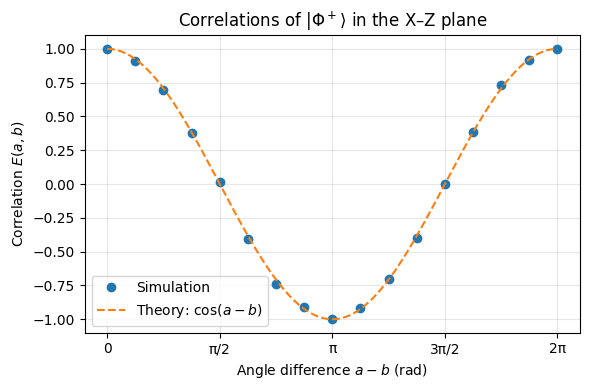

In [4]:
deltas = np.linspace(0, 2 * np.pi, 17)
E_sim = []
for k, d in enumerate(deltas):
    qc = bell_circuit(0.0, d)
    mem = sim.run(transpile(qc, sim), shots=2000, memory=True, seed_simulator=k).result().get_memory()
    E_sim.append(correlation(mem))

d_fine = np.linspace(0, 2 * np.pi, 300)
plt.figure(figsize=(6, 4))
plt.plot(deltas, E_sim, "o", label="Simulation")
plt.plot(d_fine, np.cos(d_fine), "--", label=r"Theory: $\cos(a-b)$")
plt.xlabel(r"Angle difference $a - b$ (rad)")
plt.ylabel(r"Correlation $E(a, b)$")
plt.title(r"Correlations of $|\Phi^+\rangle$ in the X–Z plane")
plt.xticks(np.arange(0, 2 * np.pi + 0.01, np.pi / 2), ["0", "π/2", "π", "3π/2", "2π"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig1_correlation_vs_angle.png", dpi=200)
plt.show()

## 2. Protocol

Each round, Alice picks one of two angles and Bob one of three, uniformly at random:

| Party | Setting 0 | Setting 1 | Setting 2 |
|---|---|---|---|
| Alice | $a_0 = 0$ | $a_1 = \pi/2$ | |
| Bob | $b_0 = \pi/4$ | $b_1 = -\pi/4$ | $b_2 = 0$ |

- **Key rounds** $(a_0, b_2)$: both measure Z, so outcomes agree on an ideal channel. These form the raw key (1/6 of rounds).
- **Test rounds** $(a_i, b_j)$ with $i, j \in \{0, 1\}$: used to estimate

```latex
S = E(a_0,b_0) + E(a_0,b_1) + E(a_1,b_0) - E(a_1,b_1),
```

  which is $2\sqrt2 \approx 2.83$ for an ideal Bell pair and at most 2 for any classical (local) model.
- Rounds $(a_1, b_2)$ are discarded.

**Implementation.** Settings are drawn per round. Rounds sharing a setting pair are run as one circuit with that many shots, which is statistically equivalent for independent rounds and is also how the hardware runs are batched in notebook 02.

In [5]:
A_ANGLES = [0.0, np.pi / 2]
B_ANGLES = [np.pi / 4, -np.pi / 4, 0.0]
KEY_PAIR = (0, 2)
CHSH_PAIRS = [(0, 0), (0, 1), (1, 0), (1, 1)]
CHSH_SIGNS = {(0, 0): 1, (0, 1): 1, (1, 0): 1, (1, 1): -1}


def e91_circuit(i, j, eve=None):
    # eve: None, or 'Z' / 'X' = intercept-resend on Bob's qubit in that basis
    qc = QuantumCircuit(2, 3)          # bit 2 stores Eve's outcome
    qc.h(0)
    qc.cx(0, 1)
    qc.barrier()
    if eve is not None:
        if eve == "X":
            qc.h(1)
        qc.measure(1, 2)
        if eve == "X":
            qc.h(1)
        qc.barrier()
    qc.ry(-A_ANGLES[i], 0)
    qc.ry(-B_ANGLES[j], 1)
    qc.measure([0, 1], [0, 1])
    return qc


def run_e91(n_rounds=6000, noise_p=0.0, eve_fraction=0.0, seed=1, backend=None):
    rng = np.random.default_rng(seed)
    a_set = rng.integers(0, 2, n_rounds)
    b_set = rng.integers(0, 3, n_rounds)
    eve_on = rng.random(n_rounds) < eve_fraction
    eve_basis = np.where(rng.integers(0, 2, n_rounds) == 0, "Z", "X")

    if backend is None:
        backend = sim
        if noise_p > 0:
            nm = NoiseModel()
            nm.add_all_qubit_quantum_error(depolarizing_error(noise_p, 2), ["cx"])
            backend = AerSimulator(noise_model=nm)

    alice = np.zeros(n_rounds, dtype=int)
    bob = np.zeros(n_rounds, dtype=int)

    # group rounds by (Alice setting, Bob setting, Eve action) and run each group once
    groups = {}
    for r in range(n_rounds):
        key = (int(a_set[r]), int(b_set[r]), eve_basis[r] if eve_on[r] else None)
        groups.setdefault(key, []).append(r)
    for g, ((i, j, eve), rounds) in enumerate(sorted(groups.items(), key=lambda kv: str(kv[0]))):
        qc = e91_circuit(i, j, eve)
        mem = backend.run(transpile(qc, backend), shots=len(rounds), memory=True,
                          seed_simulator=seed * 100 + g).result().get_memory()
        for r, s in zip(rounds, mem):
            alice[r] = int(s[-1])
            bob[r] = int(s[-2])

    # CHSH estimate from test rounds
    E = {}
    for (i, j) in CHSH_PAIRS:
        m = (a_set == i) & (b_set == j)
        E[(i, j)] = float(np.mean((1 - 2 * alice[m]) * (1 - 2 * bob[m])))
    S = sum(CHSH_SIGNS[p] * E[p] for p in CHSH_PAIRS)

    # sifted key from key rounds
    km = (a_set == KEY_PAIR[0]) & (b_set == KEY_PAIR[1])
    key_a, key_b = alice[km], bob[km]
    qber = float(np.mean(key_a != key_b))

    return {"E": E, "S": S, "qber": qber, "key_a": key_a, "key_b": key_b,
            "n_key": int(km.sum()), "n_test": int(sum(((a_set == i) & (b_set == j)).sum()
                                                       for i, j in CHSH_PAIRS))}

## 3. Key rates

Two asymptotic key rates (secret bits per sifted key bit) are compared.

**Device-independent (DI)**, which trusts neither the source nor the measurement devices and relies on the observed $S$ (Acín et al., 2007, collective attacks):

```latex
r_{\text{DI}} = 1 - h(Q) - h\!\left(\frac{1 + \sqrt{(S/2)^2 - 1}}{2}\right)
```

**Device-dependent (BBM92)**, which assumes the measurements are the intended qubit measurements:

```latex
r_{\text{BBM92}} = 1 - 2\,h(Q)
```

Here $h$ is the binary entropy and $Q$ the QBER. Under white noise of visibility $v$, $S = 2\sqrt2\, v$ and $Q = (1-v)/2$. The DI rate then vanishes at $Q \approx 7.1\%$ and the BBM92 rate at $Q \approx 11\%$.

In [6]:
def h(x):
    x = np.clip(x, 1e-12, 1 - 1e-12)
    return float(-x * np.log2(x) - (1 - x) * np.log2(1 - x))


def rate_di(S, Q):
    if S <= 2:
        return 0.0
    S = min(S, 2 * np.sqrt(2))
    return max(0.0, 1 - h(Q) - h((1 + np.sqrt((S / 2) ** 2 - 1)) / 2))


def rate_bbm92(Q):
    return max(0.0, 1 - 2 * h(Q))


def report(res, label=""):
    print(f"{label}")
    for p in CHSH_PAIRS:
        print(f"  E(a{p[0]}, b{p[1]}) = {res['E'][p]:+.3f}")
    print(f"  S = {res['S']:.3f}   (classical bound 2, quantum maximum {2 * np.sqrt(2):.3f})")
    print(f"  sifted key bits = {res['n_key']},  test rounds = {res['n_test']}")
    print(f"  QBER = {res['qber']:.4f}")
    print(f"  r_DI = {rate_di(res['S'], res['qber']):.3f}   r_BBM92 = {rate_bbm92(res['qber']):.3f}")

## 4. Results

### 4.1 Ideal run

In [7]:
res = run_e91(n_rounds=6000, seed=1)
report(res, "Ideal channel, 6000 rounds")
print("  Alice key (first 32):", "".join(map(str, res["key_a"][:32])))
print("  Bob key   (first 32):", "".join(map(str, res["key_b"][:32])))

Ideal channel, 6000 rounds
  E(a0, b0) = +0.691
  E(a0, b1) = +0.749
  E(a1, b0) = +0.741
  E(a1, b1) = -0.698
  S = 2.880   (classical bound 2, quantum maximum 2.828)
  sifted key bits = 1013,  test rounds = 3961
  QBER = 0.0000
  r_DI = 1.000   r_BBM92 = 1.000
  Alice key (first 32): 01110010100100000001110011111111
  Bob key   (first 32): 01110010100100000001110011111111


### 4.2 Depolarizing noise

A two-qubit depolarizing error of strength $p$ is attached to the CNOT that creates the pair, giving visibility $v = 1 - p$. Expected: $S = 2\sqrt2(1-p)$ and $Q = p/2$.

p = 0.00   S = 2.761 (theory 2.828)   QBER = 0.000 (theory 0.000)
p = 0.05   S = 2.649 (theory 2.687)   QBER = 0.029 (theory 0.025)
p = 0.10   S = 2.548 (theory 2.546)   QBER = 0.058 (theory 0.050)
p = 0.15   S = 2.408 (theory 2.404)   QBER = 0.087 (theory 0.075)
p = 0.20   S = 2.377 (theory 2.263)   QBER = 0.097 (theory 0.100)
p = 0.25   S = 2.109 (theory 2.121)   QBER = 0.131 (theory 0.125)
p = 0.30   S = 1.945 (theory 1.980)   QBER = 0.143 (theory 0.150)
p = 0.35   S = 1.836 (theory 1.838)   QBER = 0.177 (theory 0.175)
p = 0.40   S = 1.699 (theory 1.697)   QBER = 0.205 (theory 0.200)


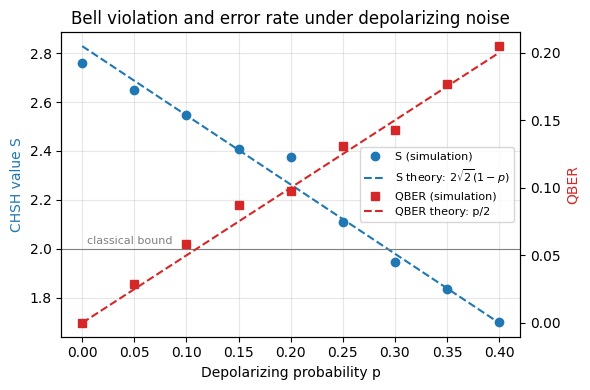

In [8]:
p_values = np.linspace(0, 0.4, 9)
S_vals, Q_vals, rdi_vals, rbb_vals = [], [], [], []
for k, p in enumerate(p_values):
    r = run_e91(n_rounds=6000, noise_p=p, seed=10 + k)
    S_vals.append(r["S"]); Q_vals.append(r["qber"])
    rdi_vals.append(rate_di(r["S"], r["qber"])); rbb_vals.append(rate_bbm92(r["qber"]))
    print(f"p = {p:.2f}   S = {r['S']:.3f} (theory {2 * np.sqrt(2) * (1 - p):.3f})   "
          f"QBER = {r['qber']:.3f} (theory {p / 2:.3f})")

p_fine = np.linspace(0, 0.4, 200)
fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.plot(p_values, S_vals, "o", color="tab:blue", label="S (simulation)")
ax1.plot(p_fine, 2 * np.sqrt(2) * (1 - p_fine), "--", color="tab:blue", label=r"S theory: $2\sqrt{2}(1-p)$")
ax1.axhline(2, color="gray", linewidth=0.8)
ax1.text(0.005, 2.02, "classical bound", color="gray", fontsize=8)
ax1.set_xlabel("Depolarizing probability p")
ax1.set_ylabel("CHSH value S", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(p_values, Q_vals, "s", color="tab:red", label="QBER (simulation)")
ax2.plot(p_fine, p_fine / 2, "--", color="tab:red", label="QBER theory: p/2")
ax2.set_ylabel("QBER", color="tab:red")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, fontsize=8, loc="center right")
ax1.set_title("Bell violation and error rate under depolarizing noise")
ax1.grid(alpha=0.3)
fig.tight_layout()
plt.savefig("fig2_chsh_qber_vs_noise.png", dpi=200)
plt.show()

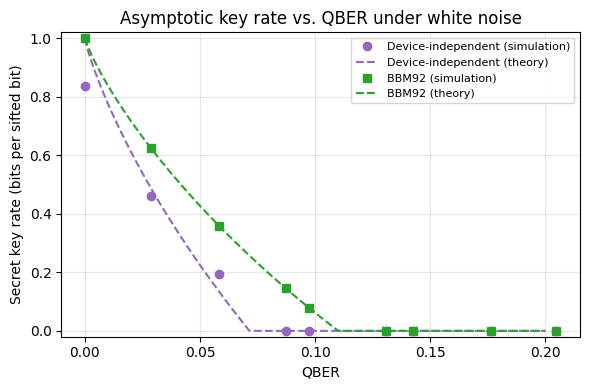

In [9]:
Q_theory = p_fine / 2
rdi_theory = [rate_di(2 * np.sqrt(2) * (1 - p), p / 2) for p in p_fine]
rbb_theory = [rate_bbm92(p / 2) for p in p_fine]

plt.figure(figsize=(6, 4))
plt.plot(Q_vals, rdi_vals, "o", color="tab:purple", label="Device-independent (simulation)")
plt.plot(Q_theory, rdi_theory, "--", color="tab:purple", label="Device-independent (theory)")
plt.plot(Q_vals, rbb_vals, "s", color="tab:green", label="BBM92 (simulation)")
plt.plot(Q_theory, rbb_theory, "--", color="tab:green", label="BBM92 (theory)")
plt.xlabel("QBER")
plt.ylabel("Secret key rate (bits per sifted bit)")
plt.title("Asymptotic key rate vs. QBER under white noise")
plt.ylim(-0.02, 1.02)
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig3_key_rate_vs_qber.png", dpi=200)
plt.show()

### 4.3 Intercept-resend eavesdropper

On a fraction $f$ of rounds, Eve measures Bob's qubit in a random Z or X basis and re-prepares it. This breaks the entanglement on those rounds: averaging the two cases gives $E(a,b) = \cos(a-b)/2$, so

```latex
S = 2\sqrt2\,(1 - f/2), \qquad Q = f/4.
```

The Bell violation disappears ($S \le 2$) once $f \gtrsim 0.59$, and the DI key rate reaches zero much earlier.

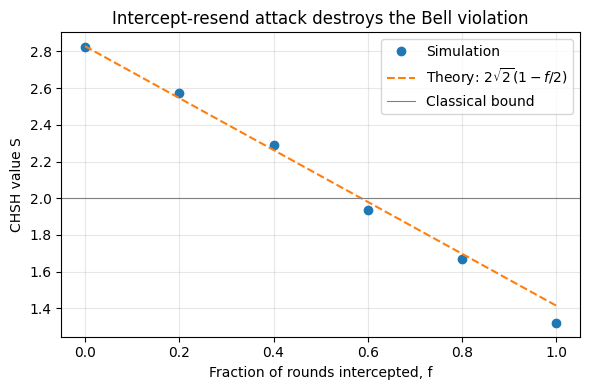

f = 0.0   S = 2.826   theory = 2.828
f = 0.2   S = 2.572   theory = 2.546
f = 0.4   S = 2.290   theory = 2.263
f = 0.6   S = 1.934   theory = 1.980
f = 0.8   S = 1.671   theory = 1.697
f = 1.0   S = 1.321   theory = 1.414


In [10]:
f_values = np.linspace(0, 1, 6)
S_eve = [run_e91(n_rounds=6000, eve_fraction=f, seed=50 + k)["S"] for k, f in enumerate(f_values)]
f_fine = np.linspace(0, 1, 200)

plt.figure(figsize=(6, 4))
plt.plot(f_values, S_eve, "o", label="Simulation")
plt.plot(f_fine, 2 * np.sqrt(2) * (1 - f_fine / 2), "--", label=r"Theory: $2\sqrt{2}(1-f/2)$")
plt.axhline(2, color="gray", linewidth=0.8, label="Classical bound")
plt.xlabel("Fraction of rounds intercepted, f")
plt.ylabel("CHSH value S")
plt.title("Intercept-resend attack destroys the Bell violation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig4_chsh_vs_eve.png", dpi=200)
plt.show()

for f, s in zip(f_values, S_eve):
    print(f"f = {f:.1f}   S = {s:.3f}   theory = {2 * np.sqrt(2) * (1 - f / 2):.3f}")

## 5. Discussion

- Measured correlations follow $\cos(a-b)$, and the ideal protocol gives $S \approx 2\sqrt2$ with zero QBER.
- Depolarizing noise lowers $S$ and raises the QBER together. The device-independent key rate falls to zero near 7% QBER, earlier than the device-dependent BBM92 rate near 11%: DI security trusts less, so it tolerates less noise.
- An intercept-resend eavesdropper reduces $S$, so the Bell test detects her without any assumption about how she attacks.

**Next.** Notebook 02 runs the same protocol on an IBM quantum processor. The hardware $S$ and QBER determine whether a positive DI or BBM92 key rate is achievable on a real device.

**Caveat.** Alice and Bob are qubits on one processor, so locality and detection loopholes are not closed. The hardware run demonstrates the protocol and its Bell-test-based key rate estimate, not a deployed QKD link.